# Tabular — Log Jaringan / Deteksi Serangan (IDS), multikelas dengan kelas langka
**Kapan dipakai:** dari log koneksi jaringan, tebak tipe serangan (pola soal final
GEMASTIK 2023).

**Metrik:** F1 macro (semua kelas sama penting, termasuk kelas yang sangat langka).

**Data demo:** KDD Cup 99 (10%), target `kategori`: normal, dos, probe, r2l, u2r
(u2r sangat langka).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/tabular_extra/ids"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/kdd_train.csv"
TEST_CSV = f"{DATA_FOLDER}/kdd_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/kdd_test_labels.csv"   # hanya ada di data latihan

TARGET = "kategori"
ID_COL = "id"
CAT_COLS = ["protocol_type", "service", "flag"]
BYTE_COLS = ["src_bytes", "dst_bytes", "count"]       # kolom untuk dilihat di EDA
SEED = 42

## Baca data
`NUM_COLS` = semua kolom test kecuali id dan kolom kategori.

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
NUM_COLS = test.columns.drop([ID_COL] + CAT_COLS).tolist()
print("train:", train.shape, "| test:", test.shape, "|", len(NUM_COLS), "kolom angka")
missing_per_column = train.isna().sum()
print("sel kosong:", missing_per_column.sum())
train.head()

train: (15788, 43) | test: (5263, 42) | 38 kolom angka
sel kosong: 0


,id,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,kategori
0,9036,0,tcp,ftp,SF,1225,2451,0,0,0,...,116,0.45,0.02,0.00,0.00,0.0,0.0,0.00,0.0,r2l
1,9593,0,tcp,http,SF,242,336,0,0,0,...,255,1.00,0.00,0.00,0.00,0.0,0.0,0.00,0.0,normal
2,14781,2,tcp,smtp,SF,1590,328,0,0,0,...,129,0.38,0.04,0.01,0.02,0.0,0.0,0.00,0.0,normal
3,8616,0,tcp,http,REJ,0,0,0,0,0,...,52,0.88,0.03,0.02,0.00,0.0,0.0,0.88,1.0,normal
4,8800,0,tcp,private,S0,0,0,0,0,0,...,8,0.03,0.08,0.00,0.00,1.0,1.0,0.00,0.0,dos


## EDA
- Jumlah per kategori serangan.
- Proporsi serangan per protokol.
- Median ukuran data per kategori (skala log, karena angkanya sangat lebar).
- Baris kembar: koneksi dengan feature sama persis (umum di log jaringan).

In [4]:
print(train[TARGET].value_counts())
print(pd.crosstab(train["protocol_type"], train[TARGET], normalize="index").round(3))

median_bytes = train.groupby(TARGET)[BYTE_COLS].median()
print(np.log1p(median_bytes).round(2))
print("baris kembar:", train.duplicated(subset=NUM_COLS + CAT_COLS).sum())

kategori
normal    9105
dos       5666
r2l        749
probe      229
u2r         39
Name: count, dtype: int64
kategori         dos  normal  probe    r2l    u2r
protocol_type                                    
icmp           0.364   0.353  0.283  0.000  0.000
tcp            0.384   0.552  0.009  0.052  0.003
udp            0.063   0.914  0.021  0.000  0.002
          src_bytes  dst_bytes  count
kategori                             
dos            0.00       0.00   5.25
normal         5.49       6.35   1.61
probe          0.00       0.00   1.10
r2l            5.81       0.00   0.69
u2r            5.64       8.04   0.69
baris kembar: 0


## Feature domain
Tambah/hapus baris di fungsi ini untuk mencoba feature lain.
- log ukuran data, rasio data kirim/terima;
- total tingkat error;
- `tanpa_balasan` = 1 kalau server tidak mengirim data balik.

In [5]:
def add_features(table):
    table = table.copy()
    table["log_src_bytes"] = np.log1p(table["src_bytes"])
    table["log_dst_bytes"] = np.log1p(table["dst_bytes"])
    table["rasio_bytes"] = table["src_bytes"] / (table["dst_bytes"] + 1)
    table["error_total"] = table["serror_rate"] + table["rerror_rate"]
    table["tanpa_balasan"] = (table["dst_bytes"] == 0).astype(int)
    return table


train = add_features(train)
test = add_features(test)
NUM_COLS = NUM_COLS + ["log_src_bytes", "log_dst_bytes", "rasio_bytes", "error_total",
                       "tanpa_balasan"]
train[NUM_COLS[-5:]].describe().round(2)

,log_src_bytes,log_dst_bytes,rasio_bytes,error_total,tanpa_balasan
count,15788.00,15788.00,15788.00,15788.00,15788.00
mean,3.51,3.66,14464.80,0.39,0.47
std,2.99,3.66,268907.80,0.49,0.50
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00
50%,5.20,4.66,0.08,0.00,0.00
75%,5.71,7.04,0.70,1.00,1.00
max,15.45,15.46,5135678.00,1.00,1.00


## Split train / validasi

In [6]:
X = train[NUM_COLS + CAT_COLS]
y = train[TARGET]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

## Model
`class_weight="balanced"` = kelas langka diberi bobot lebih besar.
Kolom kategori diubah dengan OneHot; kategori yang muncul < 10 kali digabung jadi satu.
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [7]:
encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)
preprocess = ColumnTransformer([("cat", encoder, CAT_COLS)], remainder="passthrough")

model = LGBMClassifier(n_estimators=400, learning_rate=0.05, class_weight="balanced",
                       random_state=SEED, verbose=-1)
# model = LGBMClassifier(n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1)
# model = RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample", n_jobs=-1)
# model = ExtraTreesClassifier(n_estimators=400, class_weight="balanced", n_jobs=-1)
# model = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)
# model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced",
#                                                            max_iter=3000))

pipe = make_pipeline(preprocess, model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('lgbmclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['dos','normal','probe','r2l','u2r']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](46,)","['duration','src_bytes','dst_bytes',...,'protocol_type','service','flag']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,46
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

## Evaluasi di validasi
Confusion matrix dinormalisasi per baris: angka = proporsi tiap label asli.

F1 macro: 0.9706
              precision    recall  f1-score   support

         dos      1.000     1.000     1.000      1417
      normal      0.998     0.999     0.999      2276
       probe      0.982     0.965     0.973        57
         r2l      0.989     0.995     0.992       187
         u2r      1.000     0.800     0.889        10

    accuracy                          0.998      3947
   macro avg      0.994     0.952     0.971      3947
weighted avg      0.998     0.998     0.998      3947



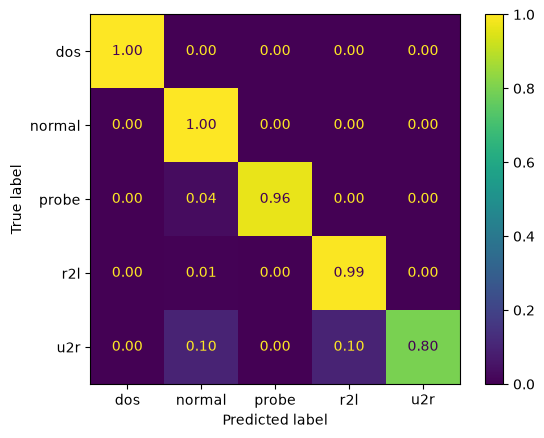

In [8]:
val_predictions = pipe.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions, digits=3))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, normalize="true",
                                        values_format=".2f")
plt.show()

## Feature paling berpengaruh (permutation importance, bahan presentasi)

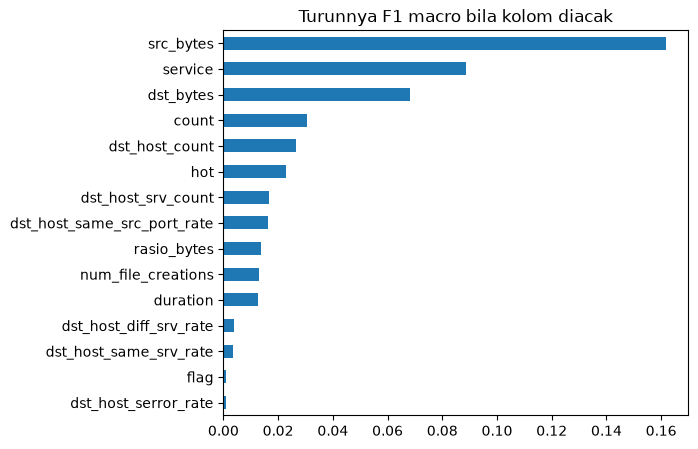

In [9]:
result = permutation_importance(pipe, X_val, y_val, scoring="f1_macro", n_repeats=3,
                                random_state=SEED, n_jobs=-1)
importance = pd.Series(result.importances_mean, index=X_val.columns)
importance = importance.sort_values()
importance.tail(15).plot.barh(figsize=(6, 5))
plt.title("Turunnya F1 macro bila kolom diacak")
plt.show()

## Latih ulang di semua data + submission

In [10]:
pipe.fit(X, y)
predictions = pipe.predict(test[NUM_COLS + CAT_COLS])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["kategori"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,kategori
0,8663,dos
1,9016,dos
2,9509,probe
3,9744,normal
4,619,normal


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [11]:
test_key = pd.read_csv(TEST_KEY_CSV)["kategori"]
print("F1 macro test (kunci latihan):", round(f1_score(test_key, predictions, average="macro"), 4))

F1 macro test (kunci latihan): 0.9824
